#Network Intrusion Detection and Anomaly Intelligence System

In [ ]:
import os
import glob

files = glob.glob('/content/*.csv')

print("Total CSV Files:", len(files))

for file in files:
    print(os.path.basename(file))

Total CSV Files: 8
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [ ]:
import pandas as pd
import glob
import os

files = glob.glob('/content/*.csv')

dataframes = []

for file in files:
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.str.strip()
    dataframes.append(temp)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset Combined Successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Combined Successfully!
Total Rows: 2830743
Total Columns: 79


Data inspection

In [ ]:
df.head(2)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,389,113095465,48,24,9668,10012,403,0,201.416667,203.548293,...,32,203985.500,575837.2562,1629110,379,13800000.0,4277541.062,16500000,6737603,BENIGN
1,389,113473706,68,40,11364,12718,403,0,167.117647,171.919413,...,32,178326.875,503426.9460,1424245,325,13800000.0,4229413.120,16500000,6945512,BENIGN


In [ ]:
df.tail(2)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
2830741,53,1048635,6,2,192,256,32,32,32.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830742,53,94939,4,2,188,226,47,47,47.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 int64  
 19  

In [ ]:
df.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,...,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06
mean,8.071483e+03,1.478566e+07,9.361160e+00,1.039377e+01,5.493024e+02,1.616264e+04,2.075999e+02,1.871366e+01,5.820194e+01,6.891013e+01,...,5.418218e+00,-2.741688e+03,8.155132e+04,4.113412e+04,1.531825e+05,5.829582e+04,8.316037e+06,5.038439e+05,8.695752e+06,7.920031e+06
std,1.828363e+04,3.365374e+07,7.496728e+02,9.973883e+02,9.993589e+03,2.263088e+06,7.171848e+02,6.033935e+01,1.860912e+02,2.811871e+02,...,6.364257e+02,1.084989e+06,6.485999e+05,3.933815e+05,1.025825e+06,5.770923e+05,2.363008e+07,4.602984e+06,2.436689e+07,2.336342e+07
min,0.000000e+00,-1.300000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-5.368707e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.300000e+01,1.550000e+02,2.000000e+00,1.000000e+00,1.200000e+01,0.000000e+00,6.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.000000e+01,3.131600e+04,2.000000e+00,2.000000e+00,6.200000e+01,1.230000e+02,3.700000e+01,2.000000e+00,3.400000e+01,0.000000e+00,...,1.000000e+00,2.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.430000e+02,3.204828e+06,5.000000e+00,4.000000e+00,1.870000e+02,4.820000e+02,8.100000e+01,3.600000e+01,5.000000e+01,2.616295e+01,...,2.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,1.200000e+08,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08,2.482000e+04,2.325000e+03,5.940857e+03,7.125597e+03,...,2.135570e+05,1.380000e+02,1.100000e+08,7.420000e+07,1.100000e+08,1.100000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


In [ ]:
df.shape

(2830743, 79)

In [ ]:
df.dtypes

,0
Destination Port,int64
Flow Duration,int64
Total Fwd Packets,int64
Total Backward Packets,int64
Total Length of Fwd Packets,int64
...,...
Idle Mean,float64
Idle Std,float64
Idle Max,int64
Idle Min,int64


In [ ]:
df.isnull().sum().sum()

np.int64(1358)

In [ ]:
df.duplicated().sum()

np.int64(308381)

In [ ]:
import numpy as np
print("Infinite Values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Infinite Values: 4376


Data cleaning

In [ ]:
# Clean Column Names
df.columns = df.columns.str.strip()


In [ ]:
# Replace infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [ ]:
# Remove Duplicate Records
df.drop_duplicates(inplace=True)

In [ ]:
# Remove rows with missing labels
df.dropna(subset=['Label'], inplace=True)

In [ ]:
# Handle missing numeric values
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())


In [ ]:
df.shape

(2522362, 79)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

Exploratory Data Analysis (EDA)

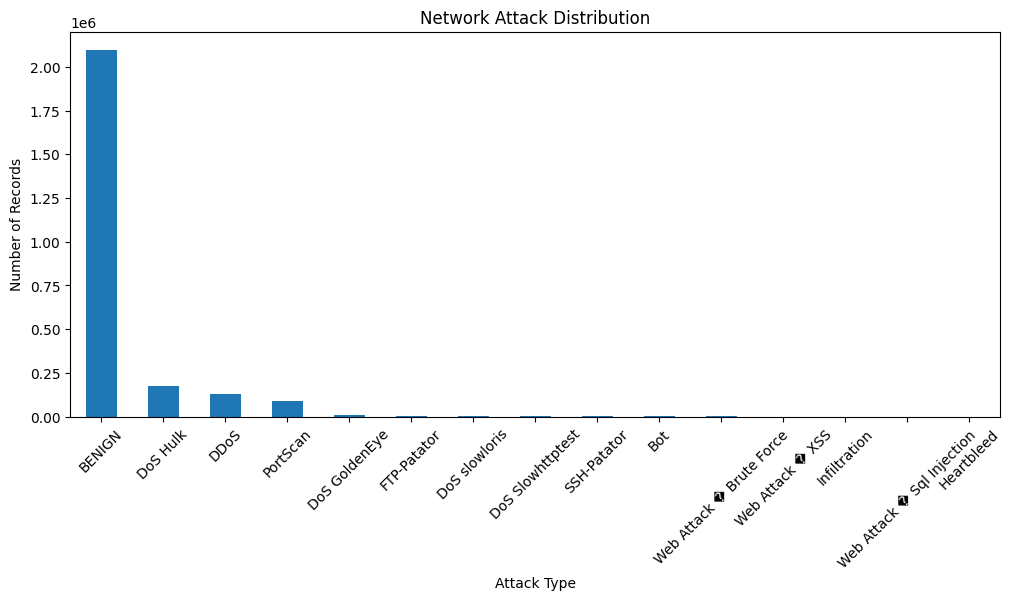

In [ ]:
#Univariate Analysis
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,5))

df['Label'].value_counts().plot(kind='bar')

plt.title('Network Attack Distribution')
plt.xlabel('Attack Type')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)

plt.show()

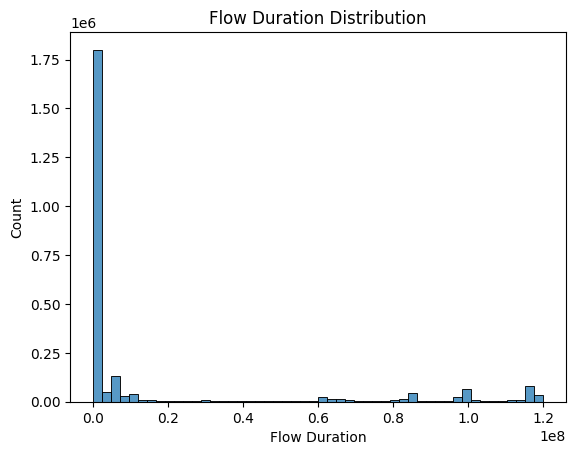

In [ ]:
sns.histplot(df['Flow Duration'], bins=50)
plt.title('Flow Duration Distribution')
plt.show()

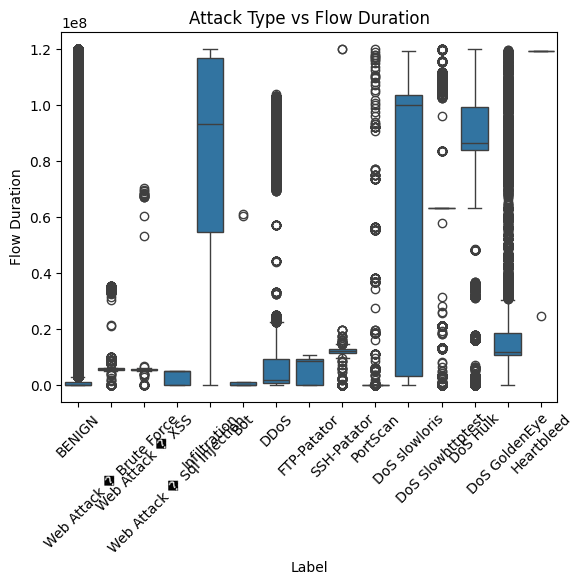

In [ ]:
#Bivariate Analysis
sns.boxplot(data=df, x='Label', y='Flow Duration')
plt.xticks(rotation=45)
plt.title('Attack Type vs Flow Duration')
plt.show()

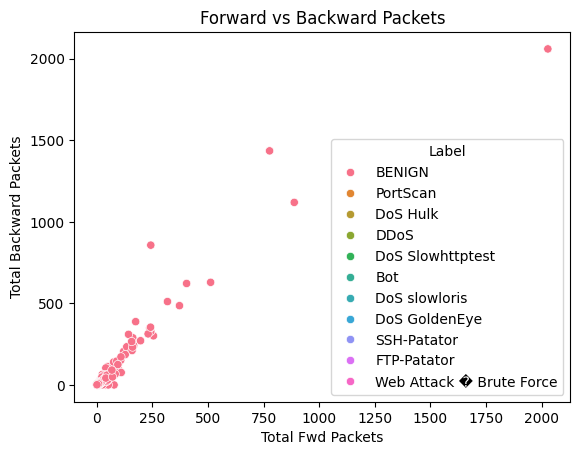

In [ ]:
sns.scatterplot(
    data=df.sample(min(5000, len(df))),
    x='Total Fwd Packets',
    y='Total Backward Packets',
    hue='Label'
)
plt.title('Forward vs Backward Packets')
plt.show()

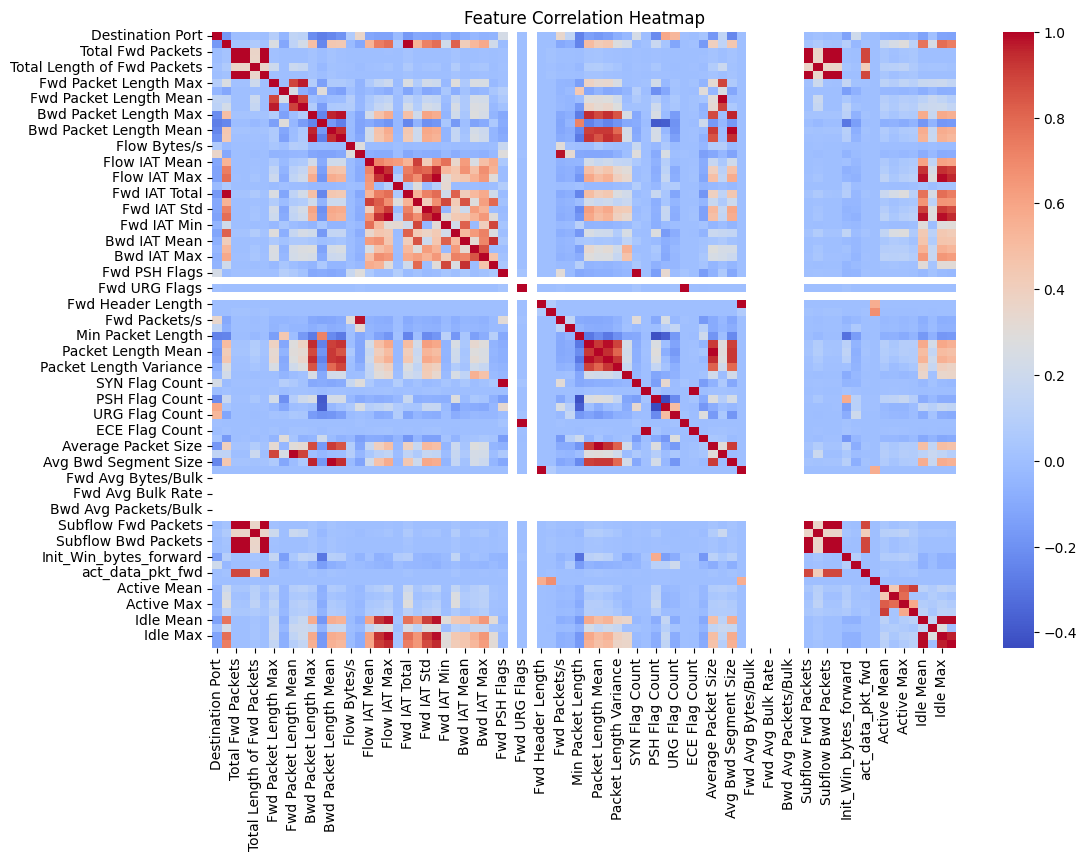

In [ ]:
#Multivariate Analysis
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap='coolwarm'
)
plt.title('Feature Correlation Heatmap')
plt.show()

Feature Engineering

In [ ]:
# Total Packets
df['Total Packets'] = (
    df['Total Fwd Packets'] + df['Total Backward Packets']
)


In [ ]:
# Total Packet Length
df['Total Packet Length'] = (
    df['Total Length of Fwd Packets'] +
    df['Total Length of Bwd Packets']
)

In [ ]:
# Average Packet Size
df['Average Packet Size'] = (
    df['Total Packet Length'] /
    df['Total Packets'].replace(0, np.nan)
)

In [ ]:
# Handle new missing values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

df['Average Packet Size'] = df['Average Packet Size'].fillna(0)


In [ ]:
df.shape

(2522362, 81)

Feature Selection & Data Preparation

In [ ]:
# Separate Features and Target

X = df.drop('Label', axis=1)
y = df['Label']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Target Classes:", y.nunique())

Features Shape: (2522362, 80)
Target Shape: (2522362,)
Target Classes: 15


In [ ]:
# Check data types

print("Numeric Columns:",
      X.select_dtypes(include=np.number).shape[1])

print("Non-Numeric Columns:",
      X.select_dtypes(exclude=np.number).shape[1])

print("\nNon-Numeric Column Names:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Numeric Columns: 80
Non-Numeric Columns: 0

Non-Numeric Column Names:
[]


In [ ]:
# Check missing values
print("Missing Values:", X.isnull().sum().sum())

# Check infinite values
print("Infinite Values:",
      np.isinf(X).sum().sum())

Missing Values: 0
Infinite Values: 0


In [ ]:
# Target Class Distribution

print("Attack Type Distribution:")
print(y.value_counts())

print("\nTotal Attack Classes:", y.nunique())

Attack Type Distribution:
Label
BENIGN                        2096484
DoS Hulk                       172849
DDoS                           128016
PortScan                        90819
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Total Attack Classes: 15


In [ ]:
# Class Imbalance Analysis

class_percentage = (y.value_counts(normalize=True) * 100)

print("Class Distribution Percentage:")
print(class_percentage.round(4))

print("\nMajority Class:", y.value_counts().idxmax())
print("Majority Percentage:",
      round(class_percentage.max(), 4), "%")

print("\nMinority Class:", y.value_counts().idxmin())
print("Minority Percentage:",
      round(class_percentage.min(), 4), "%")

Class Distribution Percentage:
Label
BENIGN                        83.1159
DoS Hulk                       6.8527
DDoS                           5.0752
PortScan                       3.6006
DoS GoldenEye                  0.4078
FTP-Patator                    0.2352
DoS slowloris                  0.2135
DoS Slowhttptest               0.2073
SSH-Patator                    0.1276
Bot                            0.0774
Web Attack � Brute Force       0.0583
Web Attack � XSS               0.0258
Infiltration                   0.0014
Web Attack � Sql Injection     0.0008
Heartbleed                     0.0004
Name: proportion, dtype: float64

Majority Class: BENIGN
Majority Percentage: 83.1159 %

Minority Class: Heartbleed
Minority Percentage: 0.0004 %


In [ ]:
from sklearn.model_selection import train_test_split

# Take a representative sample
X_sample, _, y_sample, _ = train_test_split(
    X, y,
    train_size=300000,
    stratify=y,
    random_state=42
)

print("Sample Features Shape:", X_sample.shape)
print("Sample Target Shape:", y_sample.shape)
print("\nSample Class Distribution:")
print(y_sample.value_counts())

Sample Features Shape: (300000, 80)
Sample Target Shape: (300000,)

Sample Class Distribution:
Label
BENIGN                        249348
DoS Hulk                       20558
DDoS                           15226
PortScan                       10802
DoS GoldenEye                   1223
FTP-Patator                      706
DoS slowloris                    640
DoS Slowhttptest                 622
SSH-Patator                      383
Bot                              232
Web Attack � Brute Force         175
Web Attack � XSS                  78
Infiltration                       4
Web Attack � Sql Injection         2
Heartbleed                         1
Name: count, dtype: int64


In [ ]:
# Identify classes with at least 2 records
class_counts = y_sample.value_counts()

valid_classes = class_counts[class_counts >= 2].index

In [ ]:
# Separate valid and rare classes
valid_mask = y_sample.isin(valid_classes)

X_valid = X_sample[valid_mask]
y_valid = y_sample[valid_mask]

In [ ]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_valid,
    y_valid,
    test_size=0.2,
    random_state=42,
    stratify=y_valid
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nRare Classes Excluded:")
print(class_counts[class_counts < 2])

Training Shape: (239999, 80)
Testing Shape: (60000, 80)

Rare Classes Excluded:
Label
Heartbleed    1
Name: count, dtype: int64


Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Scaled:", X_train_scaled.shape)
print("Testing Data Scaled:", X_test_scaled.shape)

Training Data Scaled: (239999, 80)
Testing Data Scaled: (60000, 80)


Random Forest Model Training

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

In [ ]:
# Train Model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [ ]:
# Random Forest Prediction

y_pred = rf_model.predict(X_test_scaled)

print("Random Forest Prediction Completed!")

Random Forest Prediction Completed!


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)

Random Forest Accuracy: 0.9973166666666666


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate Evaluation Metrics

precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Random Forest Evaluation")
print("------------------------------")
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Random Forest Evaluation
------------------------------
Precision: 0.9971661428304802
Recall: 0.9973166666666666
F1-Score: 0.9972026571531306


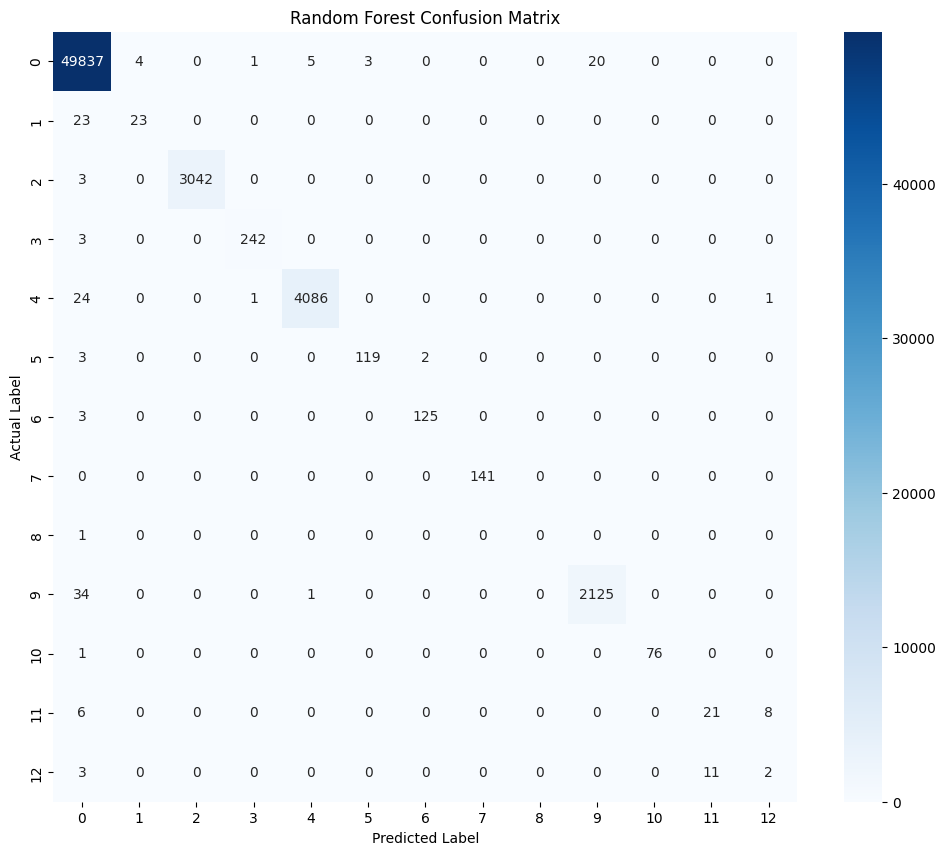

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize Confusion Matrix
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Classification Report
print("Random Forest Classification Report")
print("--------------------------------------")

print(classification_report(y_test, y_pred, zero_division=0))

Random Forest Classification Report
--------------------------------------
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00     49870
                     Bot       0.85      0.50      0.63        46
                    DDoS       1.00      1.00      1.00      3045
           DoS GoldenEye       0.99      0.99      0.99       245
                DoS Hulk       1.00      0.99      1.00      4112
        DoS Slowhttptest       0.98      0.96      0.97       124
           DoS slowloris       0.98      0.98      0.98       128
             FTP-Patator       1.00      1.00      1.00       141
            Infiltration       0.00      0.00      0.00         1
                PortScan       0.99      0.98      0.99      2160
             SSH-Patator       1.00      0.99      0.99        77
Web Attack � Brute Force       0.66      0.60      0.63        35
        Web Attack � XSS       0.18      0.12      0.15        16


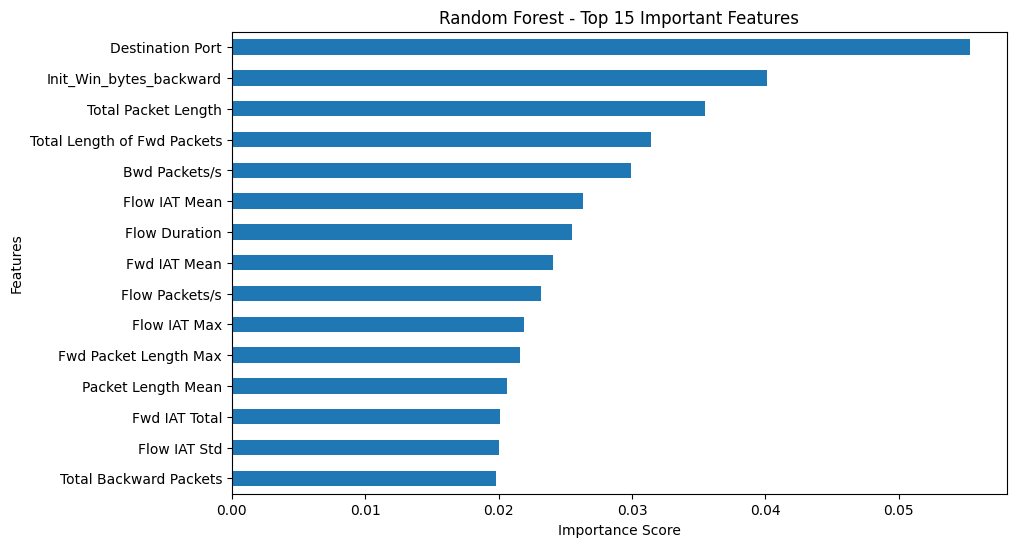

In [ ]:
# Feature Importance
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
)

# Top 15 Features
top_features = feature_importance.sort_values(
    ascending=False
).head(15)

# Visualization
plt.figure(figsize=(10, 6))

top_features.sort_values().plot(kind='barh')

plt.title("Random Forest - Top 15 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()


In [ ]:
# Random Forest Performance Summary

rf_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average='weighted', zero_division=0),
        recall_score(y_test, y_pred, average='weighted', zero_division=0),
        f1_score(y_test, y_pred, average='weighted', zero_division=0)
    ]
})

print("RANDOM FOREST MODEL PERFORMANCE")
display(rf_results)

RANDOM FOREST MODEL PERFORMANCE


,Metric,Score
0,Accuracy,0.997317
1,Precision,0.997166
2,Recall,0.997317
3,F1-Score,0.997203


Isolation Forest Model

In [ ]:
print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)
print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)


Training Data Shape: (239999, 80)
Testing Data Shape: (60000, 80)
Training Labels Shape: (239999,)
Testing Labels Shape: (60000,)


In [ ]:
from sklearn.ensemble import IsolationForest
# Create Isolation Forest Model

iso_model = IsolationForest(
    n_estimators=100,
    contamination='auto',
    random_state=42
)

print("Isolation Forest Model Created Successfully!")

Isolation Forest Model Created Successfully!


In [ ]:
# Train Isolation Forest Model

iso_model.fit(X_train_scaled)

print("Isolation Forest Model Training Completed!")

Isolation Forest Model Training Completed!


In [ ]:
# Isolation Forest Prediction

iso_pred = iso_model.predict(X_test_scaled)

print("Isolation Forest Prediction Completed!")

Isolation Forest Prediction Completed!


In [ ]:
# Anomaly Distribution Analysis

import pandas as pd

normal_count = (iso_pred == 1).sum()
anomaly_count = (iso_pred == -1).sum()

total = len(iso_pred)

print("ISOLATION FOREST ANOMALY ANALYSIS")
print("-----------------------------------")

print("Total Records:", total)
print("Normal Traffic:", normal_count)
print("Anomaly Traffic:", anomaly_count)

print("Normal Percentage:", round(normal_count / total * 100, 2), "%")
print("Anomaly Percentage:", round(anomaly_count / total * 100, 2), "%")

ISOLATION FOREST ANOMALY ANALYSIS
-----------------------------------
Total Records: 60000
Normal Traffic: 53871
Anomaly Traffic: 6129
Normal Percentage: 89.78 %
Anomaly Percentage: 10.22 %


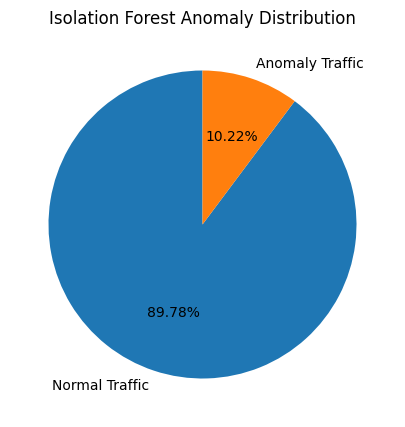

In [ ]:
import matplotlib.pyplot as plt

labels = ['Normal Traffic', 'Anomaly Traffic']
values = [normal_count, anomaly_count]

plt.figure(figsize=(7, 5))

plt.pie(
    values,
    labels=labels,
    autopct='%1.2f%%',
    startangle=90
)

plt.title("Isolation Forest Anomaly Distribution")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Convert Actual Labels into Binary Labels
y_test_binary = (y_test != 'BENIGN').astype(int)

# Convert Isolation Forest Predictions
y_pred_binary = (iso_pred == -1).astype(int)

In [ ]:
# Calculate Evaluation Metrics
iso_accuracy = accuracy_score(y_test_binary, y_pred_binary)

iso_precision = precision_score(
    y_test_binary, y_pred_binary, zero_division=0
)

iso_recall = recall_score(
    y_test_binary, y_pred_binary, zero_division=0
)

iso_f1 = f1_score(
    y_test_binary, y_pred_binary, zero_division=0
)

print("ISOLATION FOREST MODEL EVALUATION")
print("-----------------------------------")
print("Accuracy:", iso_accuracy)
print("Precision:", iso_precision)
print("Recall:", iso_recall)
print("F1-Score:", iso_f1)

ISOLATION FOREST MODEL EVALUATION
-----------------------------------
Accuracy: 0.8185833333333333
Precision: 0.43840757056616086
Recall: 0.2652517275419546
F1-Score: 0.33052463251122455


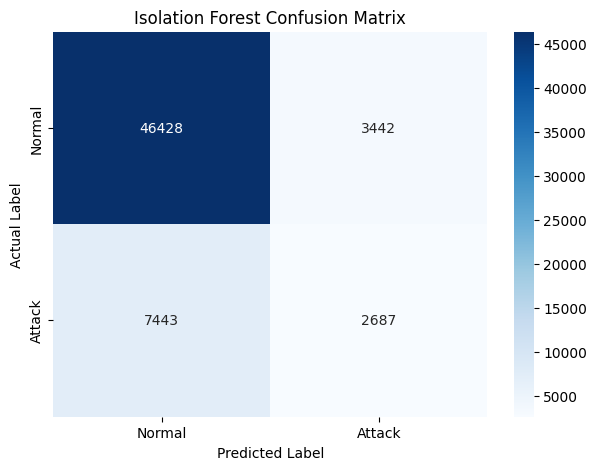

In [ ]:
# Create Confusion Matrix
cm = confusion_matrix(y_test_binary, y_pred_binary)

# Visualize
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Attack'],
    yticklabels=['Normal', 'Attack']
)

plt.title("Isolation Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Classification Report
print("ISOLATION FOREST CLASSIFICATION REPORT")
print("----------------------------------------")

print(
    classification_report(
        y_test_binary,
        y_pred_binary,
        target_names=['Normal', 'Attack'],
        zero_division=0
    )
)

ISOLATION FOREST CLASSIFICATION REPORT
----------------------------------------
              precision    recall  f1-score   support

      Normal       0.86      0.93      0.90     49870
      Attack       0.44      0.27      0.33     10130

    accuracy                           0.82     60000
   macro avg       0.65      0.60      0.61     60000
weighted avg       0.79      0.82      0.80     60000



In [ ]:
# Isolation Forest Performance Summary

iso_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [
        iso_accuracy,
        iso_precision,
        iso_recall,
        iso_f1
    ]
})

print("ISOLATION FOREST MODEL PERFORMANCE")
display(iso_results)

ISOLATION FOREST MODEL PERFORMANCE


,Metric,Score
0,Accuracy,0.818583
1,Precision,0.438408
2,Recall,0.265252
3,F1-Score,0.330525


Autoencoder Model

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

print("Autoencoder Libraries Imported Successfully!")

Autoencoder Libraries Imported Successfully!


In [ ]:
# Select Normal Traffic Only

normal_mask = (y_train == 'BENIGN').to_numpy()

X_train_normal = X_train_scaled[normal_mask]

print("AUTOENCODER DATA PREPARATION")
print("--------------------------------")
print("Original Training Data:", X_train_scaled.shape)
print("Normal Training Data:", X_train_normal.shape)
print("Data Preparation Completed!")

AUTOENCODER DATA PREPARATION
--------------------------------
Original Training Data: (239999, 80)
Normal Training Data: (199478, 80)
Data Preparation Completed!


In [ ]:
# Build Autoencoder Model

input_dim = X_train_normal.shape[1]

input_layer = Input(shape=(input_dim,))

In [ ]:
# Encoder
encoder = Dense(64, activation='relu')(input_layer)
encoder = Dense(32, activation='relu')(encoder)
encoder = Dense(16, activation='relu')(encoder)


In [ ]:
# Decoder
decoder = Dense(32, activation='relu')(encoder)
decoder = Dense(64, activation='relu')(decoder)
output_layer = Dense(input_dim, activation='linear')(decoder)

In [ ]:
# Create Model
autoencoder = Model(inputs=input_layer, outputs=output_layer)

print("Autoencoder Architecture Created Successfully!")
autoencoder.summary()

Autoencoder Architecture Created Successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 80)             │         5,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,648 (61.12 KB)

 Trainable params: 15,648 (61.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile Autoencoder Model

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

print("Autoencoder Model Compiled Successfully!")

Autoencoder Model Compiled Successfully!


In [ ]:
# Train Autoencoder Model

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_split=0.2,
    verbose=1
)

print("Autoencoder Model Training Completed!")

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.4146 - val_loss: 0.2423
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2308 - val_loss: 0.2178
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1553 - val_loss: 0.1891
Epoch 4/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.1557 - val_loss: 0.1608
Epoch 5/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1275 - val_loss: 0.1510
Epoch 6/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1322 - val_loss: 0.1634
Epoch 7/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0700 - val_loss: 0.1300
Epoch 8/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0944 - val_loss: 0.1293
Epoch 9/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0861 - val_loss: 0.1246
Epoch 10/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0727 - val_loss: 0.1165
Epoch 11/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0501 - val_loss: 0.1267
Epoch 12/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

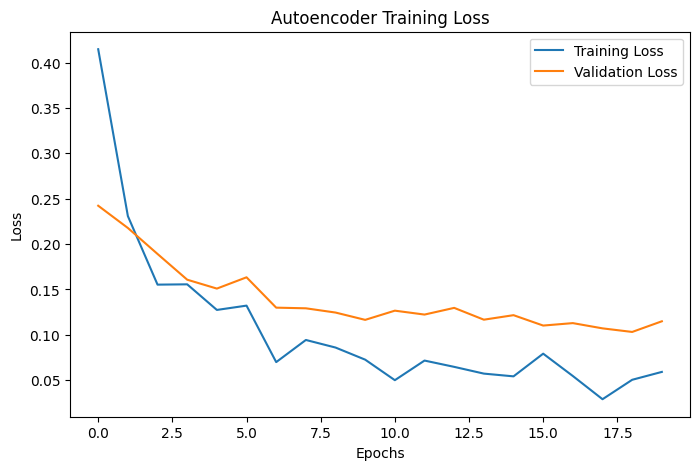

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [ ]:
# Reconstruct Test Data

X_test_reconstructed = autoencoder.predict(X_test_scaled)

print("Test Data Reconstruction Completed!")
print("Original Data Shape:", X_test_scaled.shape)
print("Reconstructed Data Shape:", X_test_reconstructed.shape)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
Test Data Reconstruction Completed!
Original Data Shape: (60000, 80)
Reconstructed Data Shape: (60000, 80)


In [ ]:
# Calculate Reconstruction Error

reconstruction_error = np.mean(
    np.square(X_test_scaled - X_test_reconstructed),
    axis=1
)

print("RECONSTRUCTION ERROR CALCULATED")
print("--------------------------------")
print("Total Records:", len(reconstruction_error))
print("Mean Error:", np.mean(reconstruction_error))
print("Maximum Error:", np.max(reconstruction_error))
print("Minimum Error:", np.min(reconstruction_error))

RECONSTRUCTION ERROR CALCULATED
--------------------------------
Total Records: 60000
Mean Error: 0.18281265717413123
Maximum Error: 3548.8209115711024
Minimum Error: 0.000265943435771724


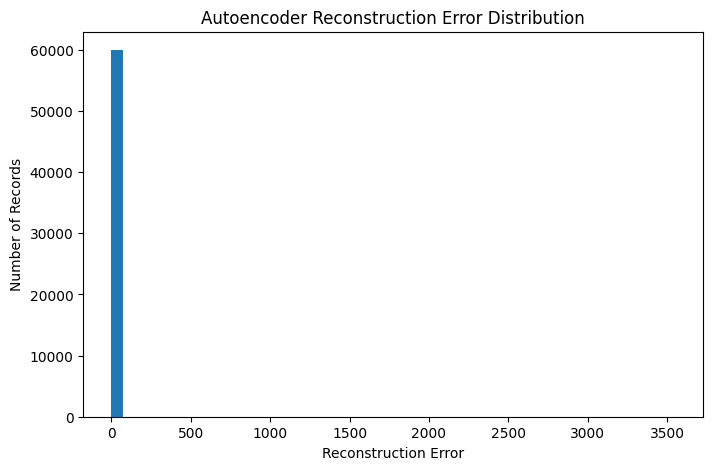

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(reconstruction_error, bins=50)

plt.title("Autoencoder Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
# Calculate Training Reconstruction Error

X_train_reconstructed = autoencoder.predict(X_train_normal)

train_error = np.mean(
    np.square(X_train_normal - X_train_reconstructed),
    axis=1
)

# Select Anomaly Threshold
threshold = np.percentile(train_error, 95)

print("AUTOENCODER THRESHOLD SELECTION")
print("--------------------------------")
print("Selected Threshold:", threshold)
print("Threshold Selection Completed!")

6234/6234 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step
AUTOENCODER THRESHOLD SELECTION
--------------------------------
Selected Threshold: 0.05435600272198897
Threshold Selection Completed!


In [ ]:
# Autoencoder Anomaly Prediction

autoencoder_pred = (
    reconstruction_error > threshold
).astype(int)

print("AUTOENCODER ANOMALY PREDICTION")
print("--------------------------------")
print("Total Records:", len(autoencoder_pred))
print("Normal Traffic:", (autoencoder_pred == 0).sum())
print("Anomaly Traffic:", (autoencoder_pred == 1).sum())

print("Anomaly Prediction Completed!")

AUTOENCODER ANOMALY PREDICTION
--------------------------------
Total Records: 60000
Normal Traffic: 51504
Anomaly Traffic: 8496
Anomaly Prediction Completed!


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

auto_accuracy = accuracy_score(y_test_binary, autoencoder_pred)
auto_precision = precision_score(y_test_binary, autoencoder_pred, zero_division=0)
auto_recall = recall_score(y_test_binary, autoencoder_pred, zero_division=0)
auto_f1 = f1_score(y_test_binary, autoencoder_pred, zero_division=0)

print("AUTOENCODER MODEL EVALUATION")
print("--------------------------------")
print("Accuracy:", auto_accuracy)
print("Precision:", auto_precision)
print("Recall:", auto_recall)
print("F1-Score:", auto_f1)

AUTOENCODER MODEL EVALUATION
--------------------------------
Accuracy: 0.8876666666666667
Precision: 0.6995056497175142
Recall: 0.5866732477788746
F1-Score: 0.6381402340813916


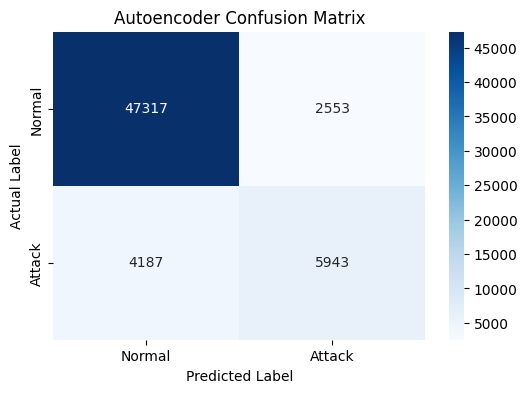

In [ ]:
cm = confusion_matrix(y_test_binary, autoencoder_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Attack'],
    yticklabels=['Normal', 'Attack']
)

plt.title("Autoencoder Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("AUTOENCODER CLASSIFICATION REPORT")
print("--------------------------------")

print(classification_report(
    y_test_binary,
    autoencoder_pred,
    target_names=['Normal', 'Attack'],
    zero_division=0
))

AUTOENCODER CLASSIFICATION REPORT
--------------------------------
              precision    recall  f1-score   support

      Normal       0.92      0.95      0.93     49870
      Attack       0.70      0.59      0.64     10130

    accuracy                           0.89     60000
   macro avg       0.81      0.77      0.79     60000
weighted avg       0.88      0.89      0.88     60000



In [ ]:
auto_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [
        auto_accuracy,
        auto_precision,
        auto_recall,
        auto_f1
    ]
})

print("AUTOENCODER RESULTS")
display(auto_results)

AUTOENCODER RESULTS


,Metric,Score
0,Accuracy,0.887667
1,Precision,0.699506
2,Recall,0.586673
3,F1-Score,0.638140


In [ ]:
autoencoder.save("autoencoder_model.keras")

print("Autoencoder Model Saved in Keras Format!")

Autoencoder Model Saved in Keras Format!


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_pred_binary = (y_pred != 'BENIGN').astype(int)

rf_binary_accuracy = accuracy_score(y_test_binary, rf_pred_binary)
rf_binary_precision = precision_score(y_test_binary, rf_pred_binary, zero_division=0)
rf_binary_recall = recall_score(y_test_binary, rf_pred_binary, zero_division=0)
rf_binary_f1 = f1_score(y_test_binary, rf_pred_binary, zero_division=0)

print("RANDOM FOREST BINARY EVALUATION")
print("--------------------------------")
print("Accuracy:", rf_binary_accuracy)
print("Precision:", rf_binary_precision)
print("Recall:", rf_binary_recall)
print("F1-Score:", rf_binary_f1)

RANDOM FOREST BINARY EVALUATION
--------------------------------
Accuracy: 0.9977166666666667
Precision: 0.9967193558007754
Recall: 0.9897334649555775
F1-Score: 0.9932141265045322


In [ ]:
rf_results_binary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [
        rf_binary_accuracy,
        rf_binary_precision,
        rf_binary_recall,
        rf_binary_f1
    ]
})

print("RANDOM FOREST BINARY RESULTS")
display(rf_results_binary)

RANDOM FOREST BINARY RESULTS


,Metric,Score
0,Accuracy,0.997717
1,Precision,0.996719
2,Recall,0.989733
3,F1-Score,0.993214


Model Comparison

In [ ]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Random Forest': [
        rf_binary_accuracy,
        rf_binary_precision,
        rf_binary_recall,
        rf_binary_f1
    ],
    'Isolation Forest': [
        iso_results.loc[0, 'Score'],
        iso_results.loc[1, 'Score'],
        iso_results.loc[2, 'Score'],
        iso_results.loc[3, 'Score']
    ],
    'Autoencoder': [
        auto_accuracy,
        auto_precision,
        auto_recall,
        auto_f1
    ]
})

print("FINAL MODEL COMPARISON")
display(comparison.round(4))

FINAL MODEL COMPARISON


,Metric,Random Forest,Isolation Forest,Autoencoder
0,Accuracy,0.9977,0.8186,0.8877
1,Precision,0.9967,0.4384,0.6995
2,Recall,0.9897,0.2653,0.5867
3,F1-Score,0.9932,0.3305,0.6381


Model Comparison Visualization

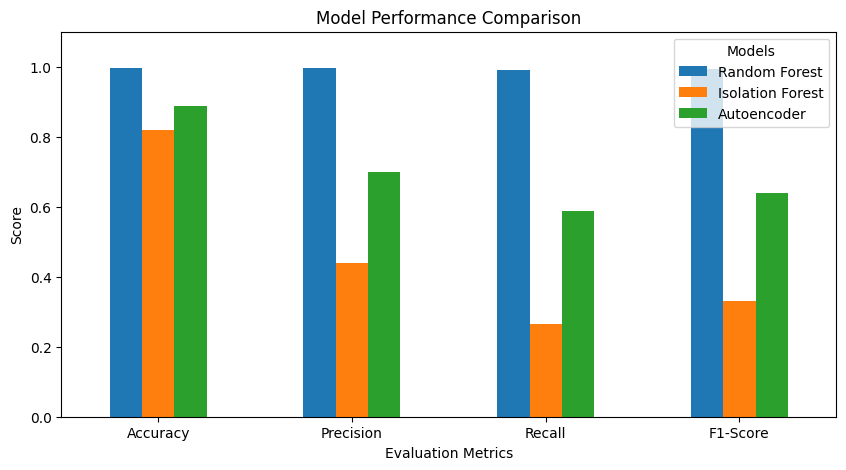

In [ ]:
comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.show()

In [ ]:
comparison.to_csv("final_model_comparison.csv", index=False)

print("Final Model Comparison Saved Successfully!")

Final Model Comparison Saved Successfully!
